# Recitation 2 | Reading an SVM decision boundary
**CS 461**

**Goal:** Read an SVM plot, identify the margin, and explain what a training point's $\alpha_i$ tells you. A point can be correctly classified and still violate the margin.

Answer Parts 1–2 **from the figures first**. Then run the code in Part 3 to check your answers. The figures are already displayed; to regenerate them, run the setup and figure cells in order (Python 3, NumPy, Matplotlib, scikit-learn).

**Reading key:** $f(x)=w^Tx+w_0$. Positive scores predict $+1$; negative scores predict $-1$; zero is the **decision boundary**. Dashed lines mark scores of $-1$ and $+1$ (the **margin boundaries**). Circles and triangles indicate true *training* labels; crosses are *new* points and have no fitted $\alpha_i$. [Course reference: Lecture 17](https://firner.com/presentations/cs461/2026-Fall/cs461_17/).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

def draw(model, X, y, names, title, probes=()):
    fig, ax = plt.subplots(figsize=(7.5, 3.4), constrained_layout=True)
    xx, yy = np.meshgrid(np.linspace(-2.7, 2.7, 180), np.linspace(-1.65, 1.9, 120))
    z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[-10,-1,1,10], colors=['#ffffff','#edf2f5','#ffffff'])
    ax.contour(xx, yy, z, levels=[-1,0,1], colors='#314253', linestyles=['--','-','--'])
    for label, marker, color in [(-1,'o','#0072b2'),(1,'^','#bf5200')]:
        ax.scatter(*X[y==label].T, marker=marker, color=color, s=68, label=f'training y={label:+d}', zorder=3)
    for (x,v), name in zip(X,names):
        ax.annotate(name,(x,v),xytext=(6,6),textcoords='offset points',weight='bold')
    for name,x,v in probes:
        ax.scatter(x,v,marker='x',s=55,c='#4c3b75',zorder=4)
        ax.annotate(name,(x,v),xytext=(6,6),textcoords='offset points')
    ax.set(xlabel='feature 1', ylabel='feature 2', title=title, xlim=(-2.7,2.7),ylim=(-1.65,1.9))
    ax.set_xticks(np.arange(-2,2.1,.5))
    ax.legend(loc='lower center',ncol=2,frameon=False)
    plt.show()

## 1 · Read the decision boundary
This separable dataset uses a large $C$, and the fitted solution matches the hard-margin SVM. All training points satisfy their margin constraints.

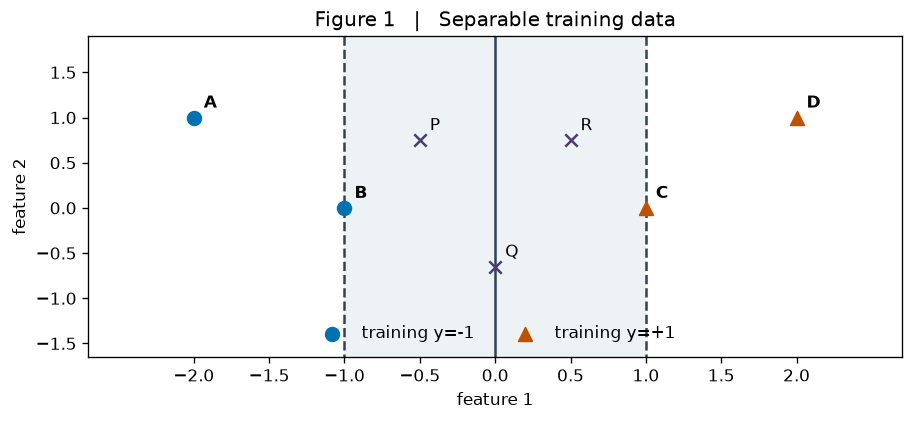

In [ ]:
X1 = np.array([[-2,1], [-1,0], [1,0], [2,1]])
y1 = np.array([-1,-1,1,1])
hard = SVC(kernel='linear', C=100).fit(X1,y1)
probes = [('P',-.5,.75), ('Q',0,-.65), ('R',.5,.75)]
draw(hard,X1,y1,'ABCD','Figure 1   |   Separable training data', probes)

**Your answers**

1. Which two **training points** lie exactly on the dashed margin boundaries? For these two points, is $\alpha_i$ **positive** or **zero**? What about the other two training points?
2. For each **new point**, read its score $f(x)$ and predicted class from the figure.

| New point | Score $f(x)$ | Predicted class ($+1$, $-1$, or boundary) |
|---|---|---|
| P | … | … |
| Q | … | … |
| R | … | … |

Why does P **not** have a fitted $\alpha$ value? …

## 2 · Read a soft margin
We add four training points and fit a new SVM with $C=2$. Let $m_i=y_i f(x_i)$ be the **signed score**. A point is classified correctly when $m_i>0$; it meets its margin constraint when $m_i\geq1$.

For this fitted soft-margin SVM:
- **Outside the margin:** if $m_i>1$, then $\alpha_i=0$.
- **Inside the margin (or misclassified):** if $m_i<1$, then $\alpha_i=C$.
- **Exactly on the margin:** if $m_i=1$, the plot alone does **not** tell us the exact $\alpha_i$. Write **check fit** in this case.

The first row below is a completed example.

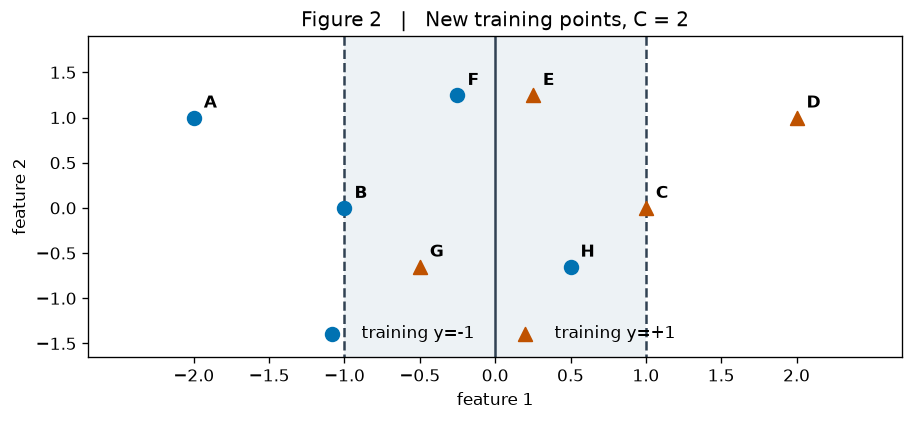

In [ ]:
X2 = np.vstack([X1, [.25,1.25], [-.25,1.25], [-.5,-.65], [.5,-.65]])
y2 = np.r_[y1, 1,-1,1,-1]
soft = SVC(kernel='linear', C=2, tol=1e-9).fit(X2,y2)
draw(soft,X2,y2,'ABCDEFGH','Figure 2   |   New training points, C = 2')

**Your answers**

Use Figure 2 to fill in the **three remaining rows**. For the last column, write **0**, **C**, or **check fit**.

| Training point | Score $f(x_i)$ | Signed score $y_i f(x_i)$ | Correctly classified? | $\alpha_i$ |
|---|---:|---:|---|---|
| **A (example)** | $-2$ | $2$ | Yes | $0$ |
| **C** | … | … | … | … |
| **E** | … | … | … | … |
| **G** | … | … | … | … |

**Explain in one sentence:** Does $\alpha_i=C$ always mean a training point was misclassified? Use **E and G** to support your answer.

Answer: …

## 3 · Check with Python
**No code to write.** Run the cell below. It prints the fitted scores and $\alpha_i$ values for the four table rows. Compare the output with your answers in Part 2; small rounding differences are fine.

In [ ]:
# Run this cell to check your answers (no edits needed).
alpha = np.zeros(len(y2))
alpha[soft.support_] = np.abs(soft.dual_coef_[0])
scores = soft.decision_function(X2)
signed_scores = y2 * scores

print('point    score   signed   alpha')
for name in 'ACEG':
    i = 'ABCDEFGH'.index(name)
    print(f'{name:>3}    {scores[i]:6.2f}   {signed_scores[i]:6.2f}   {alpha[i]:5.2f}')

**Exit ticket (one sentence):** Both E and G have $\alpha_i=C$. Why is E classified correctly while G is not?

Answer: …